In [1]:
import cv2
import numpy as np

src = cv2.imread("../image/pencils.jpg")
number1 = np.ones_like(src)*127
number2 = np.ones_like(src)*2

add = cv2.add(src,number1)
sub = cv2.subtract(src , number1)
mul = cv2.multiply(src , number2)
div = cv2.divide(src , number2)

src = np.concatenate((src,src,src,src),axis = 1)
number = np.concatenate((number1,number1,number1,number1), axis = 1)
dst = np.concatenate((add, sub , mul , div), axis = 1)
dst = np.concatenate((src,number , dst), axis = 0)

dst_re = cv2.resize(dst,dsize=(0,0),fx = 0.2, fy = 0.2, interpolation=cv2.INTER_LINEAR)
cv2.imshow("dst",dst_re)
cv2.waitKey()
cv2.destroyAllWindows()


In [ ]:
import cv2
import numpy as np

src = cv2.imread("../image/pencils.jpg")
number = np.ones_like(src)*127

_max= cv2.max(src,number)
_min=cv2.min(src,number)
_abs = cv2.absdiff(src,number)
compare = cv2.compare(src,number, cv2.CMP_GT)

src = np.concatenate((src,src,src,src),axis =1)
number = np.concatenate((number,number,number,number), axis = 1)
dst = np.concatenate((_max, _min , _abs , compare), axis = 1)
dst = np.concatenate((src,number , dst), axis = 0)

dst_re = cv2.resize(dst, dsize = (0,0), fx = 0.2, fy = 0.2, interpolation=cv2.INTER_LINEAR)
cv2.imshow("dst",dst_re)
cv2.waitKey(0)
cv2.destroyAllWindows()

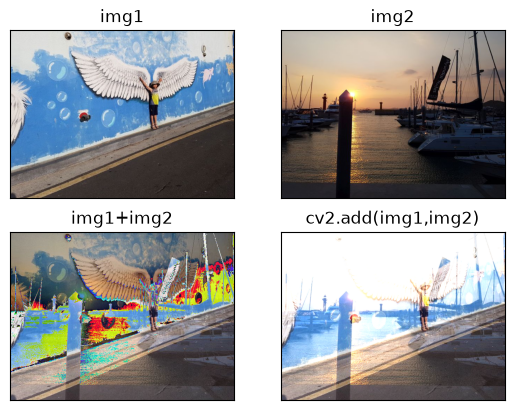

In [ ]:
import matplotlib.pylab as plt

img1 = cv2.imread("../image/wing_wall.jpg")
img2 = cv2.imread("../image/yate.jpg")

img3 = img1 +img2 
img4 = cv2.add(img1,img2) #add는 255를 넘어도 뭐한대

imgs = {"img1":img1, "img2":img2, "img1+img2" : img3 , "cv2.add(img1,img2)":img4}
for i, (k,v) in enumerate(imgs.items()):
    plt.subplot(2,2,i+1)
    plt.imshow(v[:,:,::-1])
    plt.title(k)
    plt.xticks([])
    plt.yticks([])

plt.show()

In [ ]:
alpha = 0.5

img1 = cv2.imread("../image/wing_wall.jpg")
img2 = cv2.imread("../image/yate.jpg")

blended = img1 * alpha + img2 *(1 -alpha) 
blended = blended.astype(np.uint8) 
cv2. imshow("img1 * alpha + img2 *(1 -alpha" , blended)

dst = cv2.addWeighted(img1,alpha , img2 ,(1- alpha) ,0 )
cv2.imshow( "cv2.addWeighted" , dst)

cv2.waitKey(0)
cv2.destroyAllWindows()

In [14]:
win_name = "Alpha blending"
trackbar_name = "fade"

img1 = cv2.imread("../image/man_face.jpg")
img2 = cv2.imread("../image/lion_face.jpg")

def onChange(x):
    alpha = x/100
    dst = cv2.addWeighted(img1,1-alpha, img2,alpha, 0)
    cv2.imshow(win_name,dst)



cv2.imshow(win_name,img1)
cv2.createTrackbar(trackbar_name,win_name,0,100,onChange)

cv2.waitKey()
cv2.destroyAllWindows()

In [17]:
# 비트 연산
## 틀렸음  1- 2 2-2 이미지가 같아함
src = cv2.imread("../image/analysis.jpg")
gray = cv2.cvtColor(src,cv2.COLOR_BGR2GRAY)
_,binary = cv2.threshold(gray, 127 ,255 , cv2.THRESH_BINARY)

_and = cv2.bitwise_and(gray,binary)
_or = cv2.bitwise_or(gray,binary)
_xor = cv2.bitwise_xor(gray,binary)
_not = cv2.bitwise_not(gray, binary)

src = np.concatenate((np.zeros_like(gray), gray, binary , np.zeros_like(gray)),axis = 1) 
dst = np.concatenate((_and , _or , _xor , _not), axis =1)
dst = np.concatenate((src , dst),axis =0)

dst_re = cv2.resize(dst , dsize= (0,0), fx =0.2 , fy =0.2 , interpolation=cv2.INTER_LINEAR)
cv2.imshow("dst",dst_re)
cv2.waitKey()
cv2.destroyAllWindows()

In [ ]:
img = cv2.imread("../image/yeosu.jpg")
mask = np.zeros_like(img)
cv2.circle(mask,(500,410),100,(255,255,255),-1) # -1이 도형 안을 채운다는 뜻
masked = cv2.bitwise_and(img,mask)

cv2.imshow("original",img)
cv2.imshow("mask",mask)
cv2.imshow("maksed",masked)
cv2.waitKey()
cv2.destroyAllWindows()

In [24]:
#비트연산을 이용하여 다른 점 빨리 찾기

img1 = cv2.imread("../image/robot_arm1.jpg")
img2 = cv2.imread("../image/robot_arm2.jpg")
img1_gray = cv2.cvtColor(img1,cv2.COLOR_BGR2GRAY)
img2_gray = cv2.cvtColor(img2,cv2.COLOR_BGR2GRAY)

diff = cv2.absdiff(img1_gray, img2_gray)
_,diff = cv2. threshold(diff, 1 , 255 , cv2.THRESH_BINARY)
diff_red = cv2.cvtColor(diff,cv2.COLOR_GRAY2BGR)
diff_red[:,:,2] = 0

spot = cv2.bitwise_xor(img2,diff_red)

cv2.imshow("img1",img1)
cv2.imshow("img2",img2)
cv2.imshow("diff",diff)
cv2.imshow("spot",spot)
cv2.waitKey()
cv2.destroyAllWindows()

In [39]:
img_fg = cv2.imread("../image/opencv_logo.png", cv2.IMREAD_UNCHANGED)
img_bg = cv2.imread("../image/yeosu.jpg")

_,mask = cv2.threshold(img_fg[:,:,3],1,255,cv2.THRESH_BINARY)
mask_imv = cv2.bitwise_not(mask)

img_fg = cv2.cvtColor(img_fg , cv2.COLOR_BGRA2BGR)
h,w = img_fg.shape[:2]
roi = img_bg[10:10+h, 10:10+w]

masked_fg = cv2.bitwise_and(img_fg, img_fg, mask=mask)
masked_bg = cv2.bitwise_and(roi,roi,mask=mask_imv)

added = masked_fg +masked_bg
img_bg [10:10+h,10:10+w] = added

cv2.imread("mask" , mask)
cv2.imshow("mask_inv", mask_imv)
cv2.imshow("masked_fg",masked_fg)
cv2.imshow("masked_bg",masked_bg)
cv2.imshow("added",added)
cv2.imshow("result",img_bg)
cv2.waitKey()
cv2.destroyAllWindows()

In [46]:
img1 = cv2.imread("../image/man_chromakey.jpg")
img2 = cv2.imread("../image/street.jpg")

height1, width1 = img1.shape[:2]
height2, width2 = img2.shape[:2]

x = (width2 - width1)//2
y = height2 - height1
w = x + width1
h = y+ height1

chromakey = img1[:10,:10,:]
offset = 20

hsv_chroma = cv2.cvtColor(chromakey, cv2.COLOR_BGR2HSV)
hsv_img = cv2.cvtColor(img1, cv2.COLOR_BGR2HSV)

chroma_h= hsv_chroma[:,:,0]
lower = np.array([chroma_h.min()-offset, 100,100])
upper = np.array([chroma_h.max()+offset,255,255])

mask = cv2.inRange(hsv_img,lower,upper)
mask_inv = cv2.bitwise_not(mask)
print(mask_inv)
roi = img2[y:h , x:w]
fg = cv2.bitwise_and(img1 , img1 , mask=mask_inv)
bg = cv2.bitwise_and(roi, roi, mask= mask)
img2[y:h , x:w] = fg+ bg

cv2.imshow("chromakey", img1)
cv2.imshow("added", img2)
cv2.waitKey()
cv2.destroyAllWindows()

[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]


In [ ]:
import numpy as np

src = cv2.imread("../image/road.jpg")
gray = cv2.cvtColor(src,cv2.COLOR_BGR2GRAY)
result = np.zeros((src.shape[0],256),dtype=np.uint8)

hist = cv2.calcHist([gray],[0],None,[256],[0,256])
cv2.normalize(hist,hist,0,result.shape[0],cv2.NORM_MINMAX)

for x, y in enumerate(hist):
    height = int(y[0])
    cv2.line(result, (x, result.shape[0]),(x, result.shape[0] - height), 255)

dst = np.hstack([gray, result])
dst_re = cv2.resize(dst, dsize = (0,0), fx = 0.5, fy = 0.5 , interpolation=cv2.INTER_LINEAR)
cv2.imshow("dst", dst_re)
cv2.waitKey(0)
cv2.destroyAllWindows()
    

hist.shape: (256, 1)
hist.sum() 270000.0 img.shape (450, 600)


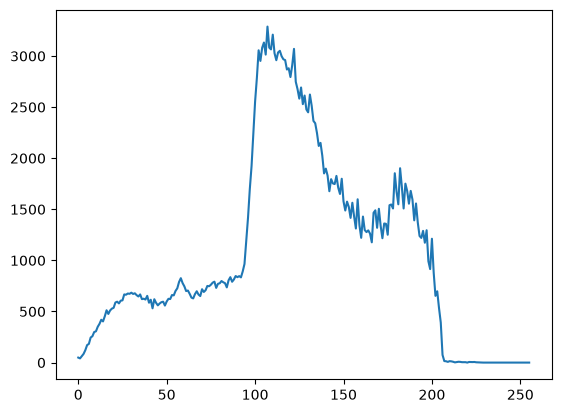

In [ ]:
img= cv2.imread("../image/mountain.jpg",cv2.IMREAD_GRAYSCALE) # 
cv2.imread("img", img)

hist = cv2.calcHist([img],[0],None,[256],[0,256])
plt.plot(hist)

print("hist.shape:",hist.shape)
print("hist.sum()",hist.sum(),"img.shape",img.shape)
plt.show()
cv2.imshow("img",img)
cv2.waitKey()
cv2.destroyAllWindows()


b
g
r


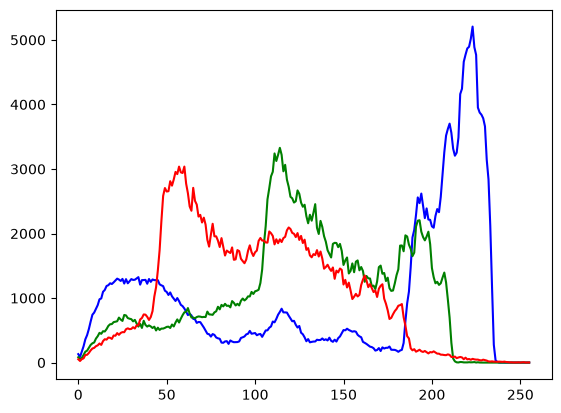

In [64]:
img= cv2.imread("../image/mountain.jpg")
cv2.imread("img", img)


channels = cv2.split(img)
colors = ("b", "g", "r")
for (ch, color) in zip (channels, colors) :
    hist = cv2.calcHist([ch],[0],None,[256],[0,256])
    print(color)
    plt.plot(hist,color = color)

plt.show() 
cv2.imshow("img",img)
cv2.waitKey()
cv2.destroyAllWindows()

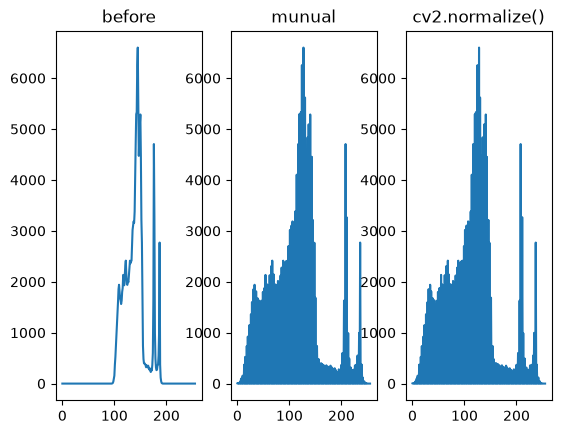

In [ ]:
import cv2
import matplotlib.pylab as plt
import numpy as np

img = cv2.imread('../image/abnormal.jpg',cv2.IMREAD_GRAYSCALE)
img_f = img.astype(np.float32)
img_norm = ((img_f - img_f.min())*(255)/(img_f.max()-img_f.min()))
img_norm = img_norm.astype(np.uint8)

img_norm2 = cv2.normalize(img,None,0,255,cv2.NORM_MINMAX)

hist = cv2.calcHist([img],[0],None,[256],[0,255])
hist_norm = cv2.calcHist([img_norm],[0],None,[256],[0,255])
hist_norm2 = cv2.calcHist([img_norm2],[0],None,[256],[0,255])

cv2.imshow("before",img)
cv2.imshow("manual",img_norm)
cv2.imshow("cv2.normalize",img_norm2)

hists = {"before":hist , "munual":hist_norm, "cv2.normalize()":hist_norm2}

for i,(k,v) in enumerate(hists.items()):
    plt.subplot(1,3,i+1)
    plt.title(k)
    plt.plot(v)

plt.show()
cv2.waitKey()
cv2.destroyAllWindows()

In [6]:
img = cv2.imread("../image/yate.jpg")
img_yuv = cv2.cvtColor(img, cv2.COLOR_BGR2YUV)
img_yuv[:,:,0] =cv2.equalizeHist(img_yuv[:,:,0])
img2 = cv2.cvtColor(img_yuv,cv2.COLOR_YUV2BGR)

cv2.imshow("before", img)
cv2. imshow("after",img2)
cv2.waitKey()
cv2.destroyAllWindows()

In [9]:
img = cv2.imread("../image/bright.jpg")
img_yuv = cv2.cvtColor(img,cv2.COLOR_BGR2YUV)

img_eq = img_yuv.copy()
img_eq[:,:,0] = cv2.equalizeHist(img_eq[:,:,0])
img_eq = cv2.cvtColor(img_eq,cv2.COLOR_YUV2BGR)

img_clahe = img_yuv.copy()
clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize= (8,8))
img_clahe[:,:,0] = clahe.apply(img_clahe[:,:,0])
img_clahe = cv2.cvtColor(img_clahe, cv2.COLOR_YUV2BGR)

cv2.imshow("before",img)
cv2.imshow("CLAHE",img_clahe)
cv2.imshow("equalizeHist",img_eq)
cv2.waitKey()
cv2.destroyAllWindows()

In [ ]:
img = cv2.imread("../image/yate.jpg")
img_yuv = cv2.cvtColor(img,cv2.COLOR_BGR2YUV)

img_eq = img_yuv.copy()
img_eq[:,:,0] = cv2.equalizeHist(img_eq[:,:,0])
img_eq = cv2.cvtColor(img_eq,cv2.COLOR_YUV2BGR)

img_clahe = img_yuv.copy()
clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize= (8,8))
img_clahe[:,:,0] = clahe.apply(img_clahe[:,:,0])
img_clahe = cv2.cvtColor(img_clahe, cv2.COLOR_YUV2BGR)

cv2.imshow("before",img)
cv2.imshow("CLAHE",img_clahe)
cv2.imshow("equalizeHist",img_eq)
cv2.waitKey(0)
cv2.destroyAllWindows()

In [15]:
# 탬플릿 매칭

src = cv2.imread("../image/hats.png",cv2.IMREAD_GRAYSCALE)
templit = cv2.imread("../image/hat.png", cv2.IMREAD_GRAYSCALE)
dst = cv2.imread("../image/hats.png")

result = cv2.matchTemplate(src, templit, cv2.TM_SQDIFF_NORMED)
minVal, maxVal, minLoc , maxLoc = cv2.minMaxLoc(result)
x,y = minLoc
h,w = templit.shape
dst = cv2.rectangle(dst , (x,y),(x+w , y+h),(0,0,255),1)

dst_re = cv2.resize(dst,dsize=(0,0),fx=0.5,fy=0.5,interpolation=cv2.INTER_LINEAR)
cv2.imshow("dst",dst_re)
cv2.imshow("dst2",src)
cv2.imshow("dst3",templit)
cv2.waitKey(0)
cv2.destroyAllWindows()